# 04 The training doctor: four broken runs, diagnosed and fixed

**Goal of this notebook.** A training run can fail in many ways, and the loss alone does not always
say why. Here we **break the training on purpose**, four times, as a colleague could do by mistake.
For each "patient" we follow the same method:

1. **Symptom**: what we measure (loss, accuracy, gradients, dead neurons...);
2. **Diagnosis**: the cause, explained with the numbers;
3. **Cure**: we fix one thing and measure again.

We use the diagnosis table of the course (session 6): `nan` means a learning rate too high; a loss
stuck at $\ln C$ means a bug or dead units; a training loss that falls while the validation loss rises
means overfitting. All patients use the same data (32 x 32 pixels) and the same seeds.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from museum_guide.config import FAST_RUN, set_seed
from museum_guide.data import channel_stats, load_images, load_split_tensors
from museum_guide.diagnostics import chance_loss, initial_loss, layer_grad_norms, make_monitor
from museum_guide.evaluation import save_results
from museum_guide.models import init_weights, make_mlp
from museum_guide.plots import PALETTE, plot_layers, save_figure
from museum_guide.recipes import train_mlp
from museum_guide.training import evaluate, fit, make_loaders, predict

set_seed()
EPOCHS = 5 if FAST_RUN else 15
N_IN = 3 * 32 * 32
loss_fn = nn.CrossEntropyLoss()

data, meta = load_split_tensors(32)
X_train, y_train = data["train"]
X_val, y_val = data["val"]
loaders = make_loaders(X_train, y_train, X_val, y_val, batch_size=64)
monitor_X, monitor_y = X_train[:256], y_train[:256]
print(f"ln 5 = {chance_loss(5):.3f}: the loss of a model that knows nothing")


def epochs_table(history, keys=("train_loss", "val_loss", "val_acc"), every=1):
    return pd.DataFrame({k: history[k] for k in keys}, index=range(1, len(history[keys[0]]) + 1)).iloc[::every].round(3)


def global_grad_norm(model):
    return math.sqrt(sum((p.grad ** 2).sum().item() for p in model.parameters() if p.grad is not None))


findings = {}

ln 5 = 1.609: the loss of a model that knows nothing


## Patient 1: a learning rate too big

**Symptom.** A colleague trains our MLP with Adam and a learning rate of 0.01 (100 times our value).

    train_loss  val_loss  val_acc  dead_layer1  dead_layer2
1        1.596     1.632    0.183          0.0     0.957031
4        1.585     1.635    0.196          0.0     0.988281
7        1.572     1.662    0.187          0.0     0.988281
10       1.578     1.619    0.183          0.0     0.992188
13       1.577     1.678    0.192          0.0     0.988281
number of validation images predicted in each class: [212, 0, 4, 0, 3]


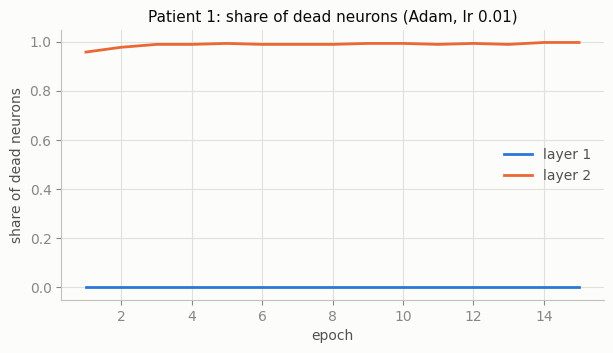

In [2]:
model_p1, h_p1 = train_mlp(loaders, lr=1e-2, epochs=EPOCHS, on_epoch_end=make_monitor(monitor_X, monitor_y))
table = epochs_table(h_p1, every=3)
table["dead_layer1"] = [d[0] for d in h_p1["dead_units"]][::3]
table["dead_layer2"] = [d[1] for d in h_p1["dead_units"]][::3]
print(table)
predicted = torch.bincount(predict(model_p1, loaders.val)[0].argmax(dim=1), minlength=5).tolist()
print("number of validation images predicted in each class:", predicted)
plot_layers(h_p1, "dead_units", "Patient 1: share of dead neurons (Adam, lr 0.01)", "share of dead neurons",
            save_as="04_p1_dead_units")

A variant of the same mistake, with plain SGD (momentum 0.9) and a learning rate of 1. We print the
loss of each **mini-batch** of the first epoch to find the first step that goes wrong.

In [3]:
torch.manual_seed(0)
m = init_weights(make_mlp(N_IN), last_scale=0.1)
opt = torch.optim.SGD(m.parameters(), lr=1.0, momentum=0.9)
batch_losses = []
m.train()
for xb, yb in loaders.train:
    opt.zero_grad()
    loss = loss_fn(m(xb), yb)
    loss.backward()
    opt.step()
    batch_losses.append(loss.item())
first_nan = next((k for k, v in enumerate(batch_losses, 1) if not math.isfinite(v)), None)
print("loss of the first mini-batches:", [f"{v:.3g}" for v in batch_losses[:first_nan or 10]])
print("first mini-batch with a nan loss:", first_nan)

loss of the first mini-batches: ['1.6', '17.9', '3.14e+03', '3.8e+05', '4.74e+09', '3.06e+13', '4.19e+23', 'nan']
first mini-batch with a nan loss: 8


**Diagnosis.** The loss stays at about 1.58, almost $\ln 5 = 1.609$, and the validation accuracy at
about 19 %: the model knows nothing. It predicts Baroque for 212 of the 219 validation images.

The monitor tells us why. After the first epoch, 96 % of the neurons of layer 2 are **dead**, and
more than 99 % at the end. A dead ReLU neuron gives 0 for every image, so its gradient is 0 and it
never comes back. With almost no living neuron, the output is nearly the same for every painting.
The cause is the step size: with Adam, each weight moves by about the learning rate at each step,
whatever the size of its gradient. With 0.01, the first steps push the weights of layer 2 so far that
every neuron becomes negative for every image.

With SGD and a learning rate of 1 the failure is louder. The loss goes 1.6, 17.9, 3 140, 380 000...
and becomes `nan` ("not a number") at the 8th mini-batch: each step overshoots more than the one
before, until the numbers are too big for the computer. This is the first line of the course table:
`nan` means a learning rate that is too high.

**Cure.** We go back to the learning rate chosen by the sweep of notebook 03 (0.0001).

In [4]:
model_c1, h_c1 = train_mlp(loaders, lr=1e-4, epochs=EPOCHS, on_epoch_end=make_monitor(monitor_X, monitor_y))
table = epochs_table(h_c1, every=3)
table["dead_layer2"] = [d[1] for d in h_c1["dead_units"]][::3]
print(table)
findings["1 learning rate too big"] = {
    "symptom": f"loss {h_p1['train_loss'][-1]:.3f} (ln 5 = 1.609), val acc {h_p1['val_acc'][-1]:.3f}, "
               f"{h_p1['dead_units'][-1][1]:.1%} dead neurons in layer 2; SGD lr 1: nan at mini-batch {first_nan}",
    "cause": "steps too big: they push the ReLU neurons of layer 2 below 0 for every image (dead), or blow up the weights",
    "cure": "learning rate 0.0001 (from the sweep)",
    "after cure": f"best val acc {max(h_c1['val_acc']):.3f}, {h_c1['dead_units'][-1][1]:.1%} dead neurons in layer 2",
}

    train_loss  val_loss  val_acc  dead_layer2
1        1.443     1.485    0.347     0.000000
4        1.223     1.414    0.429     0.003906
7        1.035     1.404    0.420     0.003906
10       0.839     1.427    0.365     0.003906
13       0.635     1.460    0.411     0.003906


## Patient 2: the forgotten `zero_grad()`

**Symptom.** A colleague wrote their own training loop, with SGD (momentum 0.9) and a reasonable
learning rate (0.001). It looks right, but one of the 5 lines is missing. We also record the norm
of the gradient used at each step.

In [5]:
grad_log = {"broken loop": [], "correct loop": []}


def forgetful_epoch(model, loader, loss_fn, optimizer, augment=None, clip_norm=None):
    model.train()
    for xb, yb in loader:
        loss = loss_fn(model(xb), yb)
        loss.backward()                  # optimizer.zero_grad() is missing before this line
        grad_log["broken loop"].append(global_grad_norm(model))
        optimizer.step()


def correct_epoch(model, loader, loss_fn, optimizer, augment=None, clip_norm=None):
    model.train()
    for xb, yb in loader:
        optimizer.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        grad_log["correct loop"].append(global_grad_norm(model))
        optimizer.step()


torch.manual_seed(0)
m = init_weights(make_mlp(N_IN), last_scale=0.1)
h_p2 = fit(m, torch.optim.SGD(m.parameters(), lr=1e-3, momentum=0.9), loaders, EPOCHS, train_epoch_fn=forgetful_epoch)
print(epochs_table(h_p2, every=3))

    train_loss  val_loss  val_acc
1        1.796     1.755    0.292
4        1.673     1.653    0.256
7        1.612     1.631    0.196
10       1.727     1.928    0.192
13       1.695     1.725    0.192


**Diagnosis.** The loss is unstable: it jumps up to 4.94 during training. In the end the model gives
almost the same answer for every painting (validation accuracy 19.2 %).

The missing line is `optimizer.zero_grad()`. In PyTorch, `loss.backward()` **adds** the new gradient
to the one already stored in each `.grad`. Without `zero_grad()`, the step at mini-batch $k$ uses the
sum of the gradients of all the $k$ batches. The plot below shows it: the gradient norm grows step
after step and is 26 times larger after 2 epochs. The optimiser takes bigger and bigger steps in old
directions.

**Cure.** We add the missing line: the 5 lines are `zero_grad`, forward, loss, `backward`, `step`.

    train_loss  val_loss  val_acc
1        1.512     1.537    0.247
4        1.406     1.456    0.370
7        1.320     1.430    0.384
10       1.233     1.417    0.379
13       1.135     1.410    0.411


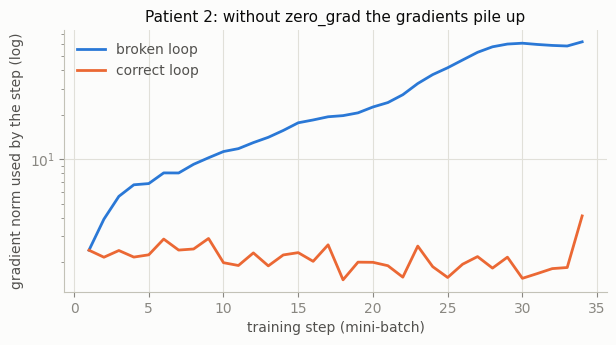

In [6]:
torch.manual_seed(0)
m = init_weights(make_mlp(N_IN), last_scale=0.1)
h_c2 = fit(m, torch.optim.SGD(m.parameters(), lr=1e-3, momentum=0.9), loaders, EPOCHS, train_epoch_fn=correct_epoch)
print(epochs_table(h_c2, every=3))

steps = len(loaders.train) * 2  # the first two epochs
fig, ax = plt.subplots(figsize=(7, 3.4))
for (name, log), color in zip(grad_log.items(), PALETTE):
    ax.plot(range(1, steps + 1), log[:steps], color=color, label=name)
ax.set_yscale("log")
ax.set_xlabel("training step (mini-batch)")
ax.set_ylabel("gradient norm used by the step (log)")
ax.set_title("Patient 2: without zero_grad the gradients pile up")
ax.legend()
save_figure(fig, "04_p2_grad_accumulation")
plt.show()
findings["2 zero_grad forgotten"] = {
    "symptom": f"loss jumps up to {max(h_p2['train_loss']):.2f}, then val acc {h_p2['val_acc'][-1]:.3f} "
               f"(one class); gradient norm x{grad_log['broken loop'][steps - 1] / grad_log['broken loop'][0]:.0f} after 2 epochs",
    "cause": "PyTorch adds each new gradient to the old ones: every step uses the sum of all past gradients",
    "cure": "optimizer.zero_grad() before loss.backward()",
    "after cure": f"loss falls smoothly to {h_c2['train_loss'][-1]:.3f}, val acc {max(h_c2['val_acc']):.3f}",
}

## Patient 3: pixels that were not standardised

**Symptom.** A colleague gives the raw pixel values (0 to 255) to the MLP, without the
standardisation of notebook 02. Same model, same initialisation.

In [7]:
raw = load_images(meta, 32).float()
is_train = torch.from_numpy(meta["split"].to_numpy() == "train")
is_val = torch.from_numpy(meta["split"].to_numpy() == "val")
raw_loaders = make_loaders(raw[is_train], y_train, raw[is_val], y_val, batch_size=64)

torch.manual_seed(0)
first_raw = initial_loss(init_weights(make_mlp(N_IN), last_scale=0.1), raw[is_train], y_train)
torch.manual_seed(0)
first_std = initial_loss(init_weights(make_mlp(N_IN), last_scale=0.1), X_train, y_train)
print(f"first loss: raw pixels {first_raw:.2f} | standardised pixels {first_std:.3f} | ln 5 = {chance_loss(5):.3f}")

torch.manual_seed(0)
m = init_weights(make_mlp(N_IN), last_scale=0.1)
h_p3_sgd = fit(m, torch.optim.SGD(m.parameters(), lr=1e-3, momentum=0.9), raw_loaders, 5)
print("SGD on raw pixels, training loss per epoch:", [f"{v:.3g}" for v in h_p3_sgd["train_loss"]])
_, h_p3 = train_mlp(raw_loaders, lr=1e-4, epochs=EPOCHS)
print("Adam on raw pixels:")
print(epochs_table(h_p3, every=3))

first loss: raw pixels 16.32 | standardised pixels 1.610 | ln 5 = 1.609


SGD on raw pixels, training loss per epoch: ['3.22e+05', '1.79', '3.06e+08', '2.23', '1.61']


Adam on raw pixels:
    train_loss  val_loss  val_acc
1        6.180     6.532    0.260
4        2.107     2.826    0.338
7        2.187     3.119    0.324
10       1.271     2.803    0.306
13       1.078     3.013    0.342


**Diagnosis.** The very first loss is **16.3** instead of $\ln 5 = 1.61$: before any training, the
model is extremely confident, and wrong. The inputs go up to 255 instead of staying around 0 (about
-2 to 2 after standardisation), so the first layer receives numbers dozens of times bigger, and the
logits are far too large.

With SGD, the gradients are huge too. The loss jumps to 322 000 after one epoch and to 306 million
after three. Adam survives, because it divides each step by the size of the recent gradients, but its
training is noisy and the validation loss stays high (about 3). Its best validation accuracy is
35.2 %. Nothing crashes, so this bug is easy to miss. The first-loss check of notebook 02 catches it
at once.

**Cure.** We standardise each colour channel with the mean and standard deviation of the training
images (this is what `load_split_tensors` does), and train the same model again.

In [8]:
mean, std = channel_stats(raw[is_train].to(torch.uint8))
print("training statistics in [0, 1] units: mean", mean.flatten().round(decimals=3).tolist(),
      "std", std.flatten().round(decimals=3).tolist())
_, h_c3 = train_mlp(loaders, lr=1e-4, epochs=EPOCHS)
print(epochs_table(h_c3, every=3))
findings["3 raw pixels"] = {
    "symptom": f"first loss {first_raw:.1f} instead of 1.6; SGD loss up to {max(h_p3_sgd['train_loss']):.2g}; "
               f"Adam noisy, best val acc {max(h_p3['val_acc']):.3f}",
    "cause": "inputs up to 255 make huge pre-activations and logits, so huge losses and gradients",
    "cure": "standardise each channel with the training mean and std",
    "after cure": f"first loss {first_std:.3f}, best val acc {max(h_c3['val_acc']):.3f}",
}

training statistics in [0, 1] units: mean [0.5519999861717224, 0.49900001287460327, 0.4309999942779541] std [0.25, 0.24199999868869781, 0.2460000067949295]


    train_loss  val_loss  val_acc
1        1.443     1.485    0.347
4        1.223     1.414    0.429
7        1.035     1.404    0.420
10       0.839     1.427    0.365
13       0.635     1.460    0.411


## Patient 4: a deep network of sigmoids

**Symptom.** A colleague wants a deeper network: 8 hidden layers of 128 neurons with the **sigmoid**
activation and PyTorch's default initialisation. We measure the gradient norm of each of the 9
layers before training, then we train it.

In [9]:
def make_deep(activation, he_init):
    layers, n_in = [nn.Flatten()], N_IN
    for _ in range(8):
        layers += [nn.Linear(n_in, 128), activation()]
        n_in = 128
    model = nn.Sequential(*layers, nn.Linear(n_in, 5))
    return init_weights(model, "he", last_scale=0.1) if he_init else model


torch.manual_seed(0)
deep_sigmoid = make_deep(nn.Sigmoid, he_init=False)
grads_sick = layer_grad_norms(deep_sigmoid, monitor_X, monitor_y)
print("gradient norm per layer:", [f"{g:.1e}" for g in grads_sick])
print(f"first layer / last layer = {grads_sick[0] / grads_sick[-1]:.1e}")
h_p4 = fit(deep_sigmoid, torch.optim.AdamW(deep_sigmoid.parameters(), lr=1e-4, weight_decay=0.0), loaders, EPOCHS)
print(epochs_table(h_p4, every=3))

gradient norm per layer: ['2.7e-06', '4.8e-06', '3.0e-05', '2.2e-04', '1.4e-03', '1.0e-02', '7.7e-02', '5.9e-01', '4.3e+00']
first layer / last layer = 6.4e-07


    train_loss  val_loss  val_acc
1        1.661     1.667    0.196
4        1.610     1.613    0.196
7        1.609     1.611    0.196
10       1.609     1.612    0.192
13       1.609     1.612    0.192


**Diagnosis.** The loss falls to 1.609, which is exactly $\ln 5$, and stays there. The network gives
the same probabilities to every image (validation accuracy 19.2 %).

The gradient of each layer shows the cause: 4.3 for the last layer but 0.0000027 for the first one, a
ratio of $6 \times 10^{-7}$. This is the **vanishing gradient** of session 5. In backpropagation, the
gradient is multiplied at each layer by the derivative of the sigmoid, which is at most 1/4. After 8
sigmoid layers almost nothing is left, so the first layers, the ones that read the pixels, do not
learn at all.

**Cure.** Same depth, but **ReLU** activations (derivative 1 for positive inputs) and **He**
initialisation (weights scaled so that the signal keeps the same size from layer to layer).

gradient norm per layer: ['1.0e+00', '2.5e-01', '2.8e-01', '3.0e-01', '3.2e-01', '3.4e-01', '3.9e-01', '5.1e-01', '5.9e+00']
first layer / last layer = 1.7e-01


    train_loss  val_loss  val_acc
1        1.518     1.549    0.265
4        1.365     1.494    0.324
7        1.101     1.485    0.329
10       0.751     1.551    0.384
13       0.416     1.823    0.356


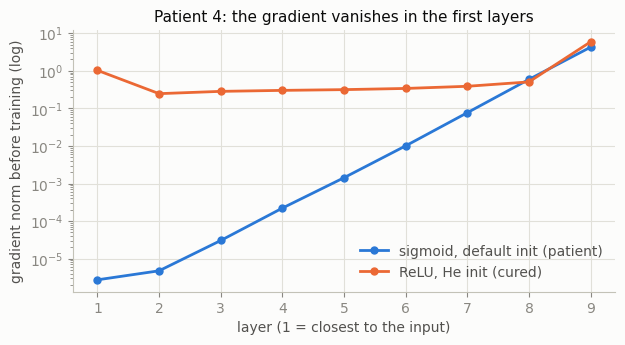

In [10]:
torch.manual_seed(0)
deep_relu = make_deep(nn.ReLU, he_init=True)
grads_cured = layer_grad_norms(deep_relu, monitor_X, monitor_y)
print("gradient norm per layer:", [f"{g:.1e}" for g in grads_cured])
print(f"first layer / last layer = {grads_cured[0] / grads_cured[-1]:.1e}")
h_c4 = fit(deep_relu, torch.optim.AdamW(deep_relu.parameters(), lr=1e-4, weight_decay=0.0), loaders, EPOCHS)
print(epochs_table(h_c4, every=3))

fig, ax = plt.subplots(figsize=(7, 3.4))
layers = range(1, len(grads_sick) + 1)
ax.plot(layers, grads_sick, "o-", color=PALETTE[0], label="sigmoid, default init (patient)")
ax.plot(layers, grads_cured, "o-", color=PALETTE[1], label="ReLU, He init (cured)")
ax.set_yscale("log")
ax.set_xlabel("layer (1 = closest to the input)")
ax.set_ylabel("gradient norm before training (log)")
ax.set_title("Patient 4: the gradient vanishes in the first layers")
ax.legend()
save_figure(fig, "04_p4_grad_per_layer")
plt.show()
findings["4 deep sigmoid"] = {
    "symptom": f"loss stuck at {h_p4['train_loss'][-1]:.3f} = ln 5, val acc {h_p4['val_acc'][-1]:.3f}; "
               f"gradient of layer 1 / layer 9 = {grads_sick[0] / grads_sick[-1]:.0e}",
    "cause": "vanishing gradient: the sigmoid derivative is at most 1/4, multiplied over 8 layers",
    "cure": "ReLU and He initialisation",
    "after cure": f"layer 1 / layer 9 = {grads_cured[0] / grads_cured[-1]:.2f}, loss {h_c4['train_loss'][-1]:.3f}, "
                  f"best val acc {max(h_c4['val_acc']):.3f}",
}

## Summary: our diagnosis table

Every number in this table was measured above.

In [11]:
summary_table = pd.DataFrame(findings).T
with pd.option_context("display.max_colwidth", None):
    display(summary_table)
save_results("04_training_doctor", findings)

,symptom,cause,cure,after cure
1 learning rate too big,"loss 1.565 (ln 5 = 1.609), val acc 0.187, 99.6% dead neurons in layer 2; SGD lr 1: nan at mini-batch 8","steps too big: they push the ReLU neurons of layer 2 below 0 for every image (dead), or blow up the weights",learning rate 0.0001 (from the sweep),"best val acc 0.438, 0.4% dead neurons in layer 2"
2 zero_grad forgotten,"loss jumps up to 4.94, then val acc 0.192 (one class); gradient norm x26 after 2 epochs",PyTorch adds each new gradient to the old ones: every step uses the sum of all past gradients,optimizer.zero_grad() before loss.backward(),"loss falls smoothly to 1.068, val acc 0.411"
3 raw pixels,"first loss 16.3 instead of 1.6; SGD loss up to 3.1e+08; Adam noisy, best val acc 0.352","inputs up to 255 make huge pre-activations and logits, so huge losses and gradients",standardise each channel with the training mean and std,"first loss 1.610, best val acc 0.438"
4 deep sigmoid,"loss stuck at 1.609 = ln 5, val acc 0.196; gradient of layer 1 / layer 9 = 6e-07","vanishing gradient: the sigmoid derivative is at most 1/4, multiplied over 8 layers",ReLU and He initialisation,"layer 1 / layer 9 = 0.17, loss 0.296, best val acc 0.393"


WindowsPath('C:/Users/benca/OneDrive - Thelio/Documents/Perso/Albert School/Deep learning/neural-network-project/reports/results/04_training_doctor.json')

**After the cures.**

- **Patient 1**: with 0.0001 almost no neuron dies (0.4 % in layer 2), and the validation accuracy
  reaches 43.8 % at its best epoch.
- **Patient 2**: the loss falls smoothly to 1.068, and the gradient norm stays at the same level.
- **Patient 3**: with standardised pixels the first loss is 1.610 (the same run as the cure of patient 1).
- **Patient 4**: with ReLU and He initialisation, the first layer gets a gradient of 1.0 (ratio 0.17),
  so every layer learns. The training loss falls to 0.296 and the best validation accuracy is 39.3 %.

Without regularisation, these cured networks then overfit, like all our MLPs: the tools of notebook
03 apply.

## What we learned

- **Four bugs, four signatures**: dead neurons (learning rate too big), growing gradients (forgotten
  `zero_grad`), a huge first loss (raw pixels), and a gradient that vanishes layer after layer (deep
  sigmoid network).
- **The loss alone is not enough.** Patients 1 and 4 show the same symptom, a loss stuck near
  $\ln 5$, for two different causes. The monitor of notebook 03 tells them apart: dead neurons for
  one, the gradient per layer for the other.
- **Some bugs are silent.** Adam on raw pixels does not crash; it just learns worse (35 % instead of
  44 %). The first-loss check catches it at once.
- **Our checklist** before we trust a run:
  1. the first loss is about $\ln C$;
  2. one batch can be learned by heart;
  3. the gradient reaches every layer;
  4. few neurons are dead;
  5. we always plot both curves, train and validation.
- **A fifth failure leaves no trace in any curve**: a painter in both the training and the test set
  makes the score look better than it is. We need a model strong enough to recognise painters to
  measure it, so we test it with the ResNet in notebook 05.